# Time Series Regression

In [24]:
#This demo is based on https://otexts.com/fpppy/nbs/07-regression.html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simple Linear Regression - Data

In [25]:
#read data from US_change.csv into pandas data frame
data = pd.read_csv('US_change.csv', parse_dates=['ds'], index_col='ds')

In [26]:
#Rename column y to "Consumption"
data.rename(columns={'y': 'Consumption'}, inplace=True)
data.head()

,Consumption,Income,Production,Savings,Unemployment,unique_id
ds,,,,,,
1970-01-01,0.618566,1.044801,-2.452486,5.299014,0.9,US_change
1970-04-01,0.451984,1.225647,-0.551459,7.789894,0.5,US_change
1970-07-01,0.872872,1.585154,-0.358652,7.403984,0.5,US_change
1970-10-01,-0.271848,-0.239545,-2.185691,1.169898,0.7,US_change
1971-01-01,1.901345,1.975925,1.909764,3.535667,-0.1,US_change


In [27]:
data.describe()

,Consumption,Income,Production,Savings,Unemployment
count,198.000000,198.000000,198.000000,198.000000,198.000000
mean,0.742482,0.728169,0.507083,1.392258,0.001010
std,0.637863,0.900393,1.521350,11.966324,0.367318
min,-2.277836,-4.084420,-6.836039,-56.471910,-0.900000
25%,0.417479,0.314376,-0.010780,-4.049088,-0.200000
50%,0.776656,0.760346,0.666085,1.349359,-0.100000
75%,1.097577,1.160228,1.295245,6.341144,0.100000
max,2.319558,4.521869,4.154295,41.607730,1.400000


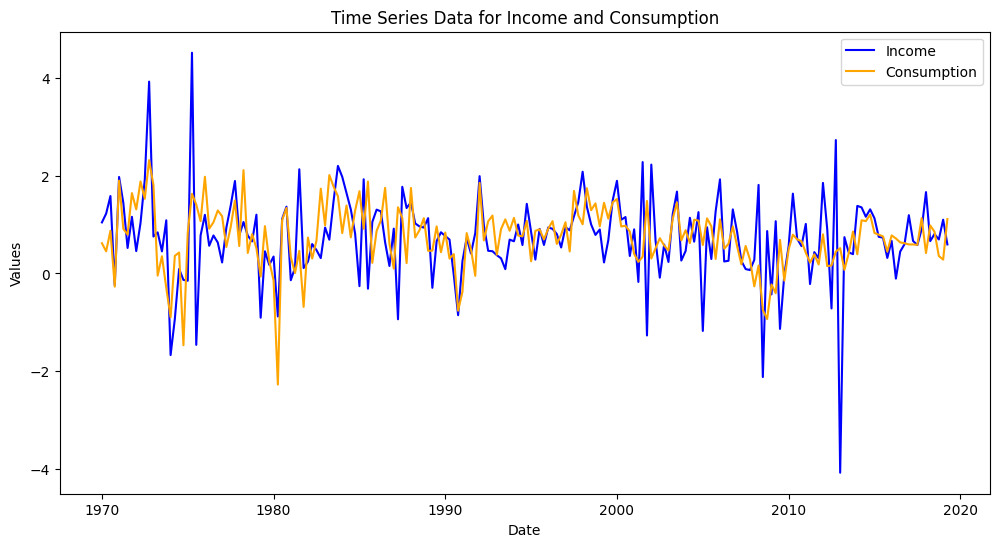

In [28]:
#plot the data as two line plots
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Income'], label='Income', color='blue')
plt.plot(data.index, data['Consumption'], label='Consumption', color='orange')
plt.title("Time Series Data for Income and Consumption")
plt.xlabel('Date')
plt.ylabel('Values')
plt.legend()
plt.show()

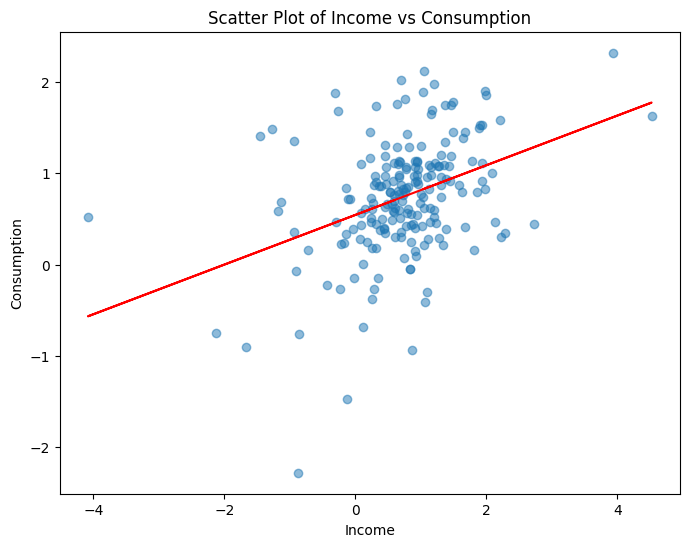

In [29]:
#show the same data in a scatter plot including a regression line
plt.figure(figsize=(8,6))
plt.scatter(data['Income'], data['Consumption'], alpha=0.5)
plt.title("Scatter Plot of Income vs Consumption")
plt.xlabel('Income')
plt.ylabel('Consumption')
#add regression line
m, b = np.polyfit(data['Income'].dropna(), data['Consumption'].dropna(), 1)
plt.plot(data['Income'], m*data['Income'] + b, color='red')
plt.show()

# Simple Linear Regression - Model

In [30]:
#calculate correlation coefficient between income and consumption
correlation = data['Income'].corr(data['Consumption'])
print(f"Correlation coefficient between Income and Consumption: {correlation:.2f}")

Correlation coefficient between Income and Consumption: 0.38


In [31]:
#create a linear regression model to predict consumption change based on income change
from sklearn.linear_model import LinearRegression

#split the data into training data (first 80%) and test data (last 20%)
train_size = int(len(data) * 0.8)
train_data = data.iloc[:train_size]
test_data = data.iloc[train_size:]

#remove NaN values from training and test data
train_data = train_data.dropna()
test_data = test_data.dropna()

model = LinearRegression()
#reshape the data for sklearn
X_train = train_data['Income'].values.reshape(-1, 1)
y_train = train_data['Consumption'].values.reshape(-1, 1)
X_test = test_data['Income'].values.reshape(-1, 1)
y_test = test_data['Consumption'].values.reshape(-1, 1)

In [32]:
#fit the model
model.fit(X_train, y_train)
#make predictions
y_pred = model.predict(X_test)

#calculate MAE
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)
print(f'Mean Absolute Error: {mae:.4f}')

Mean Absolute Error: 0.3249


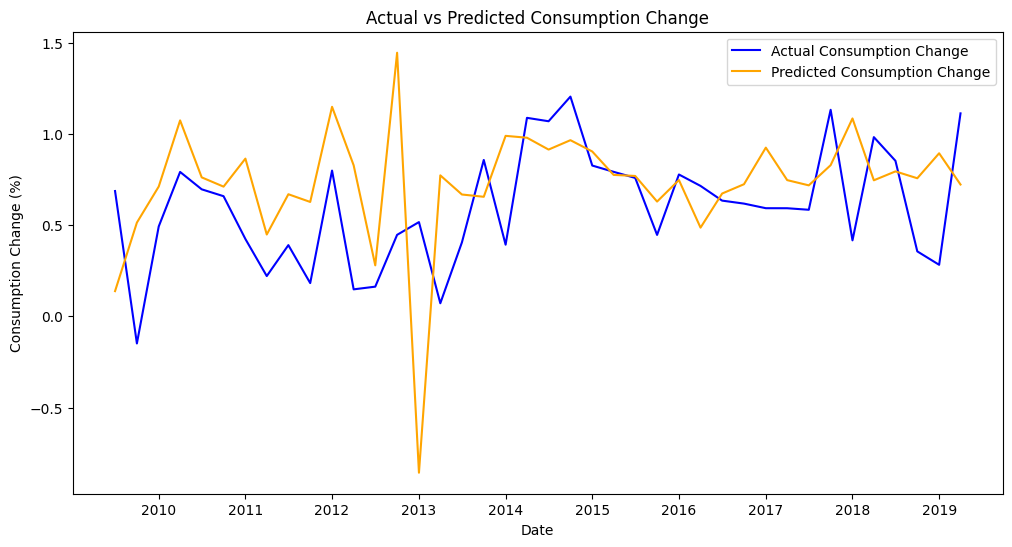

In [33]:
#plot actual vs predicted consumption change in line plot
plt.figure(figsize=(12,6))
plt.plot(test_data.index, y_test, label='Actual Consumption Change', color='blue')
plt.plot(test_data.index, y_pred, label='Predicted Consumption Change', color='orange')
plt.title("Actual vs Predicted Consumption Change")
plt.xlabel('Date')
plt.ylabel('Consumption Change (%)')
plt.legend()
plt.show()

# Multiple Linear Regression - Data

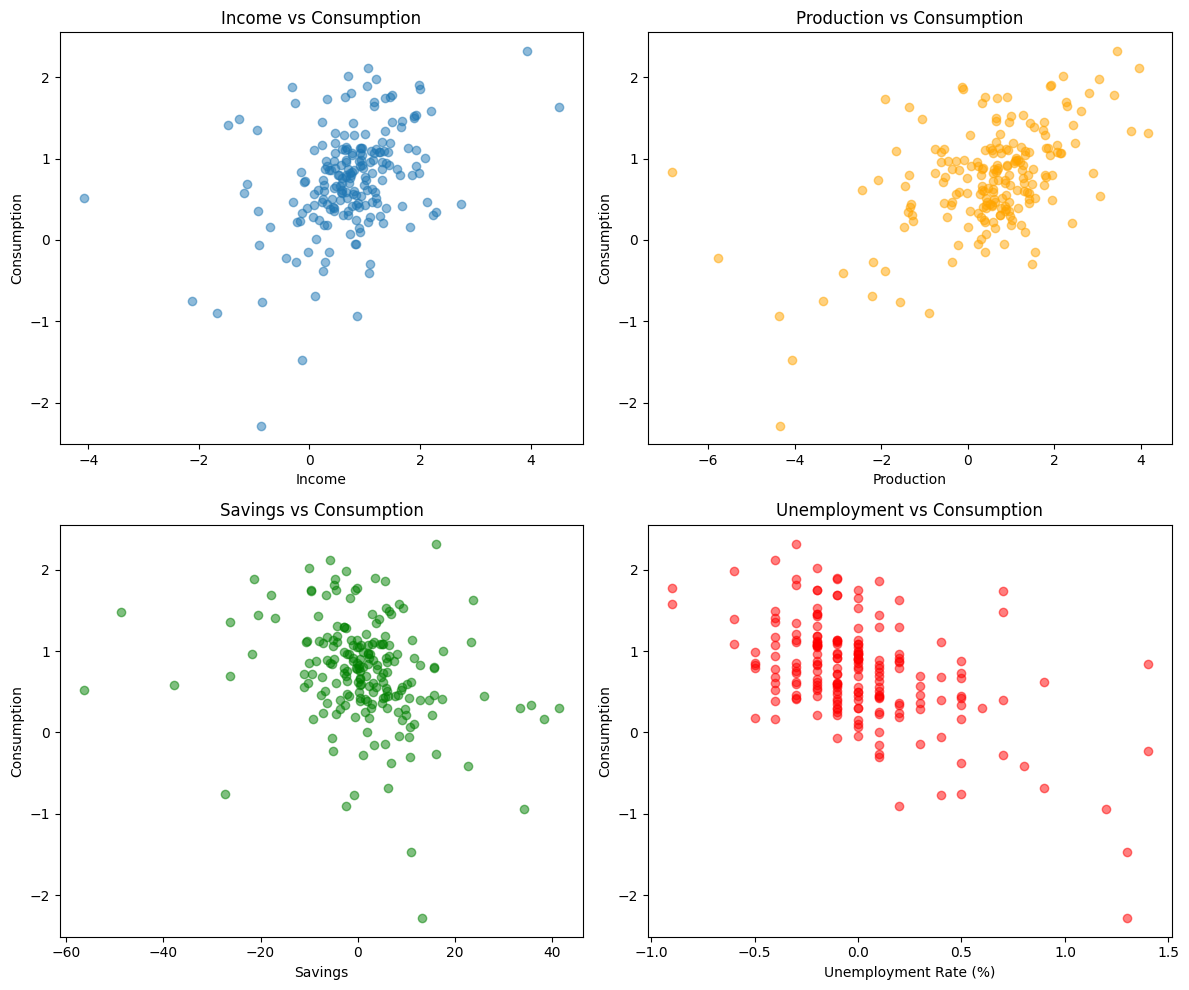

In [34]:
#create a combination of scatter plots to show the relationships between consumption_change and all other "change_variables"
#show consumption_change on the y-axis and the other variables on the x-axis
#arrange the plots in a 2x2 grid
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
axs[0, 0].scatter(data['Income'], data['Consumption'], alpha=0.5)
axs[0, 0].set_title('Income vs Consumption')
axs[0, 0].set_xlabel('Income')
axs[0, 0].set_ylabel('Consumption')
axs[0, 1].scatter(data['Production'], data['Consumption'], alpha=0.5, color='orange')
axs[0, 1].set_title('Production vs Consumption')
axs[0, 1].set_xlabel('Production')
axs[0, 1].set_ylabel('Consumption')
axs[1, 0].scatter(data['Savings'], data['Consumption'], alpha=0.5, color='green')
axs[1, 0].set_title('Savings vs Consumption')
axs[1, 0].set_xlabel('Savings')
axs[1, 0].set_ylabel('Consumption')
axs[1, 1].scatter(data['Unemployment'], data['Consumption'], alpha=0.5, color='red')
axs[1, 1].set_title('Unemployment vs Consumption')
axs[1, 1].set_xlabel('Unemployment Rate (%)')
axs[1, 1].set_ylabel('Consumption')
plt.tight_layout()
plt.show()

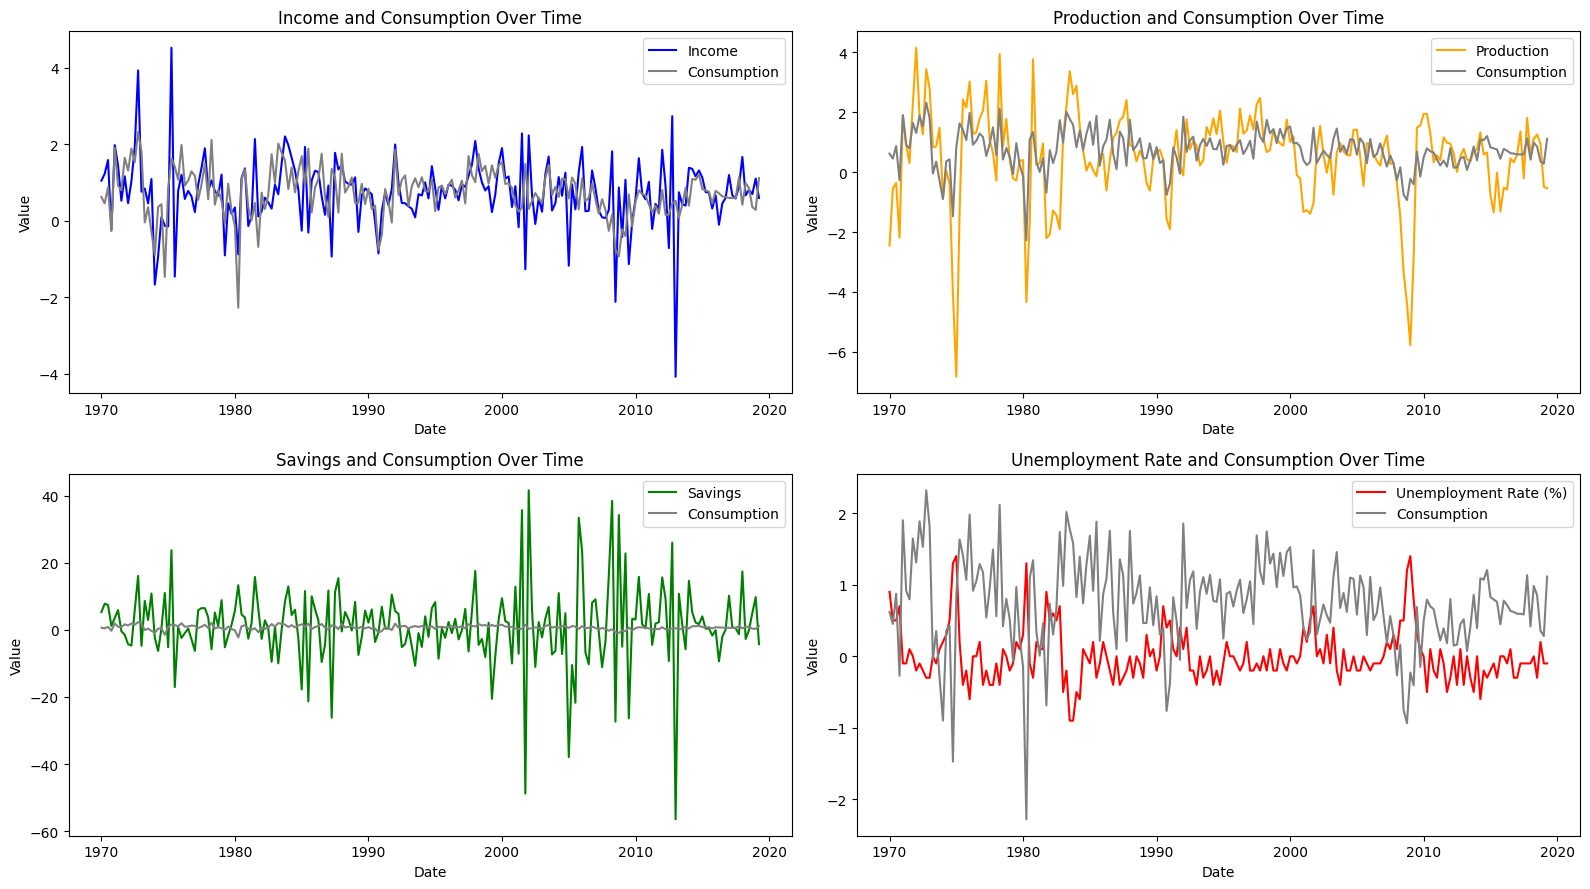

In [35]:
#Display the same data but in a 2x2grid of line plots 
#grid should be in 16:9 format
#Always combine consumption_change with one of the other change variables in one plot
#use same colors as in previous scatter plots
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
axs[0, 0].plot(data.index, data['Income'], label='Income', color='blue')
axs[0, 0].plot(data.index, data['Consumption'], label='Consumption', color='grey')
axs[0, 0].set_title('Income and Consumption Over Time')
axs[0, 0].set_xlabel('Date')
axs[0, 0].set_ylabel('Value')
axs[0, 0].legend()
axs[0, 1].plot(data.index, data['Production'], label='Production', color='orange')
axs[0, 1].plot(data.index, data['Consumption'], label='Consumption', color='grey')
axs[0, 1].set_title('Production and Consumption Over Time')
axs[0, 1].set_xlabel('Date')
axs[0, 1].set_ylabel('Value')
axs[0, 1].legend()
axs[1, 0].plot(data.index, data['Savings'], label='Savings', color='green')
axs[1, 0].plot(data.index, data['Consumption'], label='Consumption', color='grey')
axs[1, 0].set_title('Savings and Consumption Over Time')
axs[1, 0].set_xlabel('Date')
axs[1, 0].set_ylabel('Value')
axs[1, 0].legend()
axs[1, 1].plot(data.index, data['Unemployment'], label='Unemployment Rate (%)', color='red')
axs[1, 1].plot(data.index, data['Consumption'], label='Consumption', color='grey')
axs[1, 1].set_title('Unemployment Rate and Consumption Over Time')
axs[1, 1].set_xlabel('Date')
axs[1, 1].set_ylabel('Value')
axs[1, 1].legend()
plt.tight_layout()
plt.show()



# Multiple Regression - Model

In [36]:
#split the data into training data (first 80%) and test data (last 20%)
train_size = int(len(data) * 0.8)
train_data = data.iloc[:train_size]
test_data = data.iloc[train_size:]

In [37]:
#create a multiple linear regression model to predict income change based on consumption change, production change, savings change and unemployment change
from sklearn.linear_model import LinearRegression
model = LinearRegression()
#create pandas data frames for training and testing, separating features and target variable
train = pd.DataFrame({
    'Income': train_data['Income'],
    'Production': train_data['Production'],
    'Savings': train_data['Savings'],
    'Unemployment': train_data['Unemployment'],
    'Consumption': train_data['Consumption'],
})
test = pd.DataFrame({
    'Income': test_data['Income'],
    'Production': test_data['Production'],
    'Savings': test_data['Savings'],
    'Unemployment': test_data['Unemployment'],
    'Consumption': test_data['Consumption'],
})

#drop NaN values
train = train.dropna()
test = test.dropna()

train

,Income,Production,Savings,Unemployment,Consumption
ds,,,,,
1970-01-01,1.044801,-2.452486,5.299014,0.9,0.618566
1970-04-01,1.225647,-0.551459,7.789894,0.5,0.451984
1970-07-01,1.585154,-0.358652,7.403984,0.5,0.872872
1970-10-01,-0.239545,-2.185691,1.169898,0.7,-0.271848
1971-01-01,1.975925,1.909764,3.535667,-0.1,1.901345
...,...,...,...,...,...
2008-04-01,1.813508,-1.484941,38.467665,0.5,0.162019
2008-07-01,-2.123959,-3.349753,-27.365973,0.5,-0.751601
2008-10-01,0.867342,-4.371497,34.223733,1.2,-0.935007


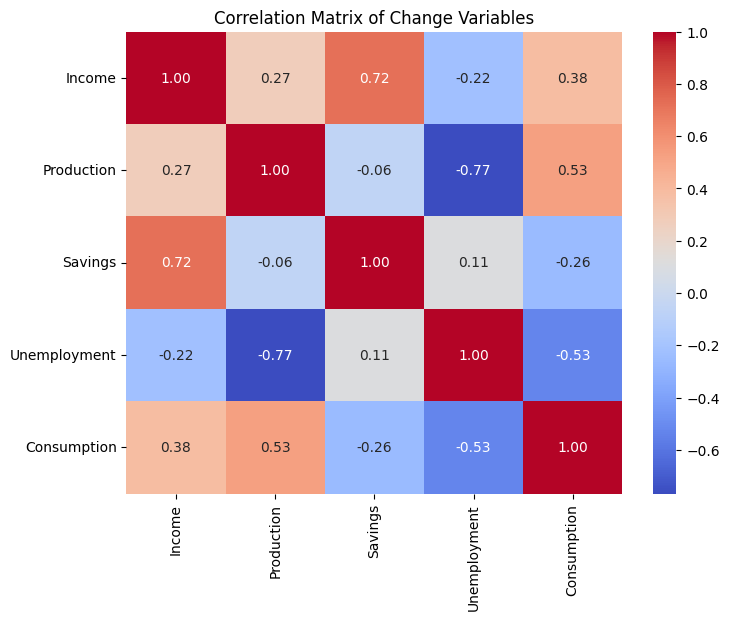

In [38]:
#create correlation matrix heatmap for all change variables
import seaborn as sns
plt.figure(figsize=(8,6))
corr = data[['Income', 'Production', 'Savings', 'Unemployment', 'Consumption']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Change Variables")
plt.show()

In [39]:
features = ['Income', 'Production', 'Savings', 'Unemployment']
target = 'Consumption'

#fit the model, use consumption as label and all other change variables as features
X_train = train[features]
y_train = train[target]
X_test = test[features]
y_test = test[target]
model.fit(X_train, y_train)

#make predictions
y_pred = model.predict(X_test)


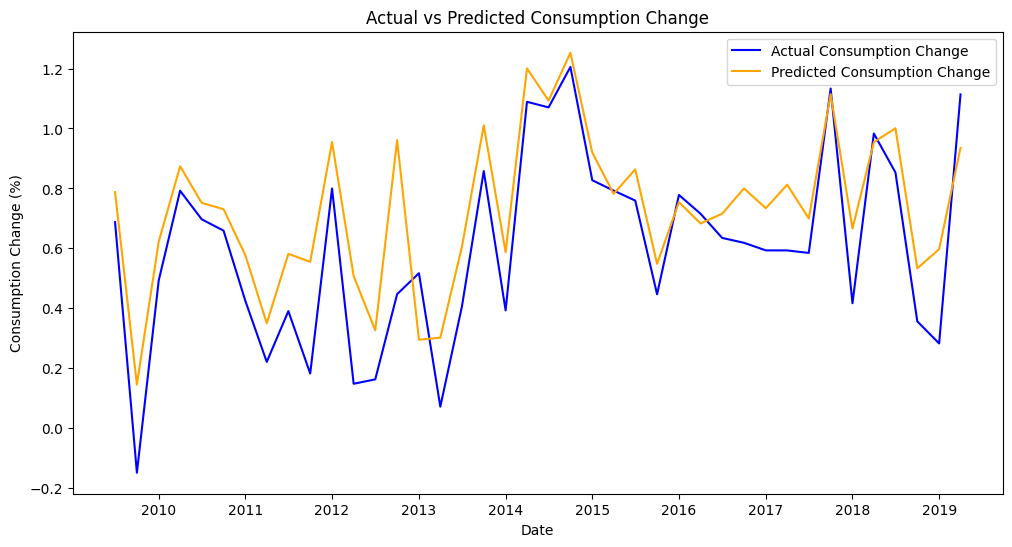

In [40]:
#plot actual vs predicted consumption change in line plot
plt.figure(figsize=(12,6))
plt.plot(test.index, y_test, label='Actual Consumption Change', color='blue')
plt.plot(test.index, y_pred, label='Predicted Consumption Change', color='orange')
plt.title("Actual vs Predicted Consumption Change")
plt.xlabel('Date')
plt.ylabel('Consumption Change (%)')
plt.legend()
plt.show()

In [41]:
#calculate MAE
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)
print(f'Mean Absolute Error: {mae:.4f}')

Mean Absolute Error: 0.1541


# Usefull additional predictors (7.4)

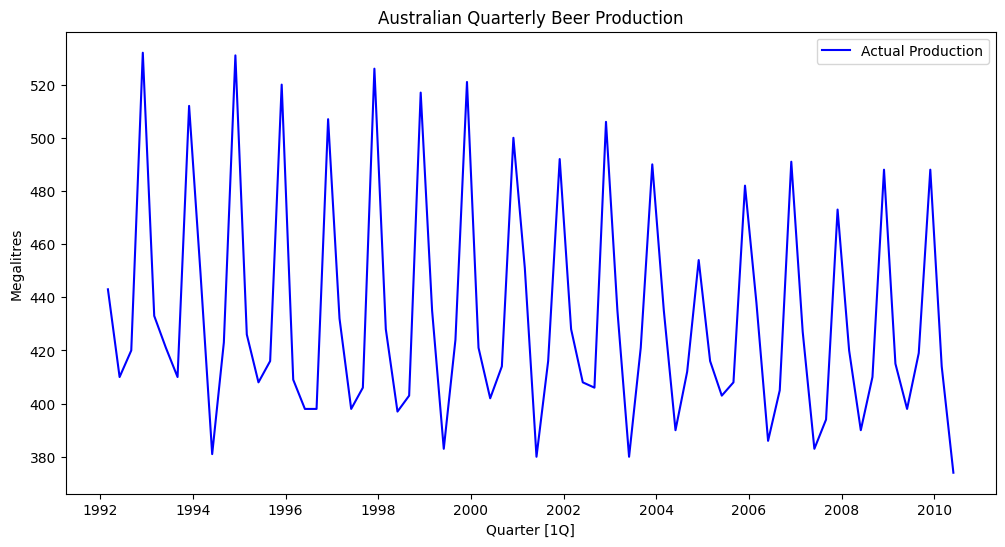

In [42]:
# Read data
aus_production = pd.read_csv("aus_production_formatted.csv",parse_dates=[1])
recent_production = aus_production.query("unique_id == 'Beer' and ds >= '1992-01-01'").reset_index(drop=True)

#plot recent production data as line plot with plot_series xlabel="Quarter [1Q]", ylabel="Megalitres", title="Australian quarterly beer production"
plt.figure(figsize=(12,6))
plt.plot(recent_production['ds'], recent_production['y'], label='Actual Production', color='blue')
plt.title("Australian Quarterly Beer Production")
plt.xlabel("Quarter [1Q]")
plt.ylabel("Megalitres")
plt.legend()
plt.show()

In [43]:
from utilsforecast.feature_engineering import trend
beer_data = recent_production.copy()
# Add trend
beer_data, _ = trend(beer_data, freq="QS-DEC")
# Add quarterly indicators
quarter = pd.get_dummies(beer_data.ds.dt.quarter, prefix="Quarter",
  drop_first=True)
beer_data = beer_data.join(quarter)
beer_data

,unique_id,ds,y,trend,Quarter_2,Quarter_3,Quarter_4
0,Beer,1992-03-01,443.0,1.0,False,False,False
1,Beer,1992-06-01,410.0,2.0,True,False,False
2,Beer,1992-09-01,420.0,3.0,False,True,False
3,Beer,1992-12-01,532.0,4.0,False,False,True
4,Beer,1993-03-01,433.0,5.0,False,False,False
...,...,...,...,...,...,...,...
69,Beer,2009-06-01,398.0,70.0,True,False,False
70,Beer,2009-09-01,419.0,71.0,False,True,False
71,Beer,2009-12-01,488.0,72.0,False,False,True
72,Beer,2010-03-01,414.0,73.0,False,False,False


In [44]:
#split into training and test data
train_size = int(len(beer_data) * 0.7)
train = beer_data.iloc[:train_size]
test = beer_data.iloc[train_size:]

features = ['trend', 'Quarter_2', 'Quarter_3', 'Quarter_4']
target = 'y'

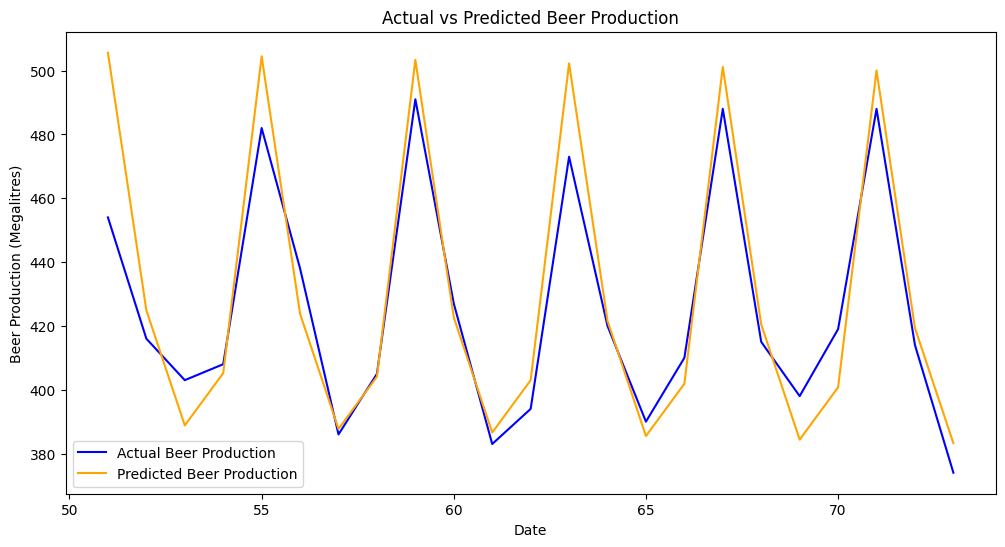

In [45]:
#train regression model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(train[features], train[target])

#make predictions
y_pred = model.predict(test[features])

#plot actual vs predicted beer production in line plot
plt.figure(figsize=(12,6))
plt.plot(test.index, test[target], label='Actual Beer Production', color='blue')
plt.plot(test.index, y_pred, label='Predicted Beer Production', color='orange')
plt.title("Actual vs Predicted Beer Production")
plt.xlabel('Date')
plt.ylabel('Beer Production (Megalitres)')
plt.legend()
plt.show()

In [46]:
#show coefficients of sklearn linear regression model
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
})
coefficients


,Feature,Coefficient
0,trend,-0.278302
1,Quarter_2,-35.798618
2,Quarter_3,-19.135696
3,Quarter_4,80.419312
